In [1]:
pip install torch pandas numpy scikit-learn matplotlib seaborn tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 113.7 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 98.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 49.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 8.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 34.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 15.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 9.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 94.9 MB/s eta 0:00:00:00:0100:01
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader , WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from tqdm import tqdm
# Set seeds
np.random.seed(42)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

#%% [markdown]
# ## 1. Configuration and Attack Mapping

#%%
CONFIG = {
    'batch_size': 512,
    'epochs': 20,
    'learning_rate': 0.001,
    'input_shape': (44, 1), # (Features, Channels)
    'use_mock_data': False, # Set to False and provide path below for real data
    # 'dataset_path': '/kaggle/input/CICIOT23/',
    'dataset_path':"/kaggle/input/ton-iot-network-dataset/train_test_network.csv",
    "temperature":2.0,
    'ae_loss_weight': 0.1 
}

# --- Detailed Mapping Strategy (From User Request) ---

ATTACK_MAPPING = {
   'normal':"Normal",
    "injection":"Injection",
    "scanning":"Scanning",
    "password":"Password",
    "ransomware":"Ransomware",
    'xss':"XSS",
    'backdoor':"Backdoor",
    'dos':"Dos",
    'ddos':"DDos",
    'mitm':'Mitm'
}


Using device: cuda


In [2]:
# data=pd.read_csv(CONFIG["dataset_path"])

In [3]:
#data.head()

In [4]:

SEEN_CLASSES = ['Normal','Ransomware','Backdoor','Injection','DDos','Password','Dos','XSS']
UNSEEN_CLASSES = ['Scanning']

print(f"Training on: {SEEN_CLASSES}")
print(f"Testing detection of: {UNSEEN_CLASSES}")

Training on: ['Normal', 'Ransomware', 'Backdoor', 'Injection', 'DDos', 'Password', 'Dos', 'XSS']
Testing detection of: ['Scanning']


In [5]:
    CONFIG

{'batch_size': 512,
 'epochs': 20,
 'learning_rate': 0.001,
 'input_shape': (44, 1),
 'use_mock_data': False,
 'dataset_path': '/kaggle/input/ton-iot-network-dataset/train_test_network.csv',
 'temperature': 2.0,
 'ae_loss_weight': 0.1}

In [6]:
class IoTDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [7]:
config=CONFIG

In [8]:
# add the balance of the classes in the training of the data 

In [9]:
def balanced_sample(df, label_col, max_n=300_000, seed=42):
    n = min(max_n, len(df))
    cls_counts = df[label_col].value_counts()
    classes = cls_counts.index.tolist()
    k = len(classes)

    # base per-class target
    per = n // k
    remainder = n % k

    rng = np.random.default_rng(seed)
    picked = []

    # first pass: take up to 'per' from each class
    remaining_df_parts = []
    for cls in classes:
        g = df[df[label_col] == cls]
        take = min(per, len(g))
        picked.append(g.sample(n=take, random_state=seed))
        # keep leftovers for remainder distribution
        if len(g) > take:
            remaining_df_parts.append(g.drop(picked[-1].index))

    out = pd.concat(picked, ignore_index=True)

    # distribute remainder from remaining rows (still respecting class variety)
    if remainder > 0:
        if remaining_df_parts:
            remaining = pd.concat(remaining_df_parts, ignore_index=True)
            # sample remainder uniformly across remaining rows
            extra = remaining.sample(n=min(remainder, len(remaining)), random_state=seed)
            out = pd.concat([out, extra], ignore_index=True)

    # final shuffle
    out = out.sample(frac=1, random_state=seed).reset_index(drop=True)
    return out

In [10]:


def load_and_process(config):
    try:
        print("Loading dataset...")
        df = pd.read_csv(config["dataset_path"])
        
        # --- 1. CLEANING DATA ---
        # Replace the dash '-' with NaN so Pandas understands it is missing info
        df.replace('-', np.nan, inplace=True)
        
        # --- 2. MAP LABELS ---
        # Ensure 'type' column exists before mapping
        if 'type' not in df.columns:
            raise ValueError("The column 'type' is missing from the dataset.")
            
        df['category'] = df['type'].map(ATTACK_MAPPING)
        
        # Handle cases where mapping might have failed (NaN categories)
        # If your mapping dict is incomplete, fill with 'Attack' or drop
        df.dropna(subset=['category'], inplace=True) 
        
        # filter out Mitm if needed
        df = df[df['category'] != 'Mitm']

        # --- 3. FEATURE ENGINEERING ---
        # Drop columns that are not useful for learning or leak info
        # 'src_ip' and 'dst_ip' are usually dropped because the model will memorize 
        # specific IPs instead of learning attack patterns.
        drop_cols = ['src_ip', 'dst_ip', 'label', 'category']
        
        # Separate features (X_raw) and targets
        X_raw = df.drop(columns=[c for c in drop_cols if c in df.columns], axis=1)
        y = df['category'].values
        y_raw_label = df['label'].values # Keep original label if needed

        # --- 4. ENCODING (Convert Strings to Numbers) ---
        # We need to process X_raw to remove strings before Scaling
        
        # Identify columns that are not numbers (object type)
        cat_columns = X_raw.select_dtypes(include=['object']).columns
        
        # Fill missing values:
        # For numerical columns, fill NaN with 0
        # For categorical columns, fill NaN with "None"
        for col in X_raw.columns:
            if col in cat_columns:
                X_raw[col] = X_raw[col].fillna("None")
            else:
                X_raw[col] = X_raw[col].fillna(0)

        # Apply Label Encoding to categorical columns (proto, service, state, etc.)
        # This converts 'tcp' -> 1, 'udp' -> 2, etc.
        le_features = LabelEncoder()
        for col in cat_columns:
            # Fit transform converts strings to numbers
            X_raw[col] = le_features.fit_transform(X_raw[col].astype(str))

        # --- 5. SCALING ---
        # Now X_raw contains only numbers, so StandardScaler will work
        X = X_raw.values
        scaler = StandardScaler()
        X = scaler.fit_transform(X)

        # --- 6. RESHAPE ---
        # Reshape for Sequence: (Samples, Features, 1)
        X = X.reshape(X.shape[0], X.shape[1], 1)
        
        print(f"Data Processed. Shape: {X.shape}")
        return X, y, y_raw_label

    except FileNotFoundError:
        print(f"File not found at {config['dataset_path']}. Check path.")
        return None, None, None
    except Exception as e:
        print(f"An error occurred: {e}")
        return None, None, None

X, y, y_raw = load_and_process(CONFIG)

#%% [markdown]
# ## 3. Splitting: Training (Seen Only) vs Testing (Mixed)

#%%
seen_indices = np.isin(y, SEEN_CLASSES)
unseen_indices = ~seen_indices

X_seen = X[seen_indices]
y_seen = y[seen_indices]

le = LabelEncoder()
y_seen_enc = le.fit_transform(y_seen)
num_classes = len(le.classes_)

X_train, X_temp, y_train, y_temp = train_test_split(X_seen, y_seen_enc, test_size=0.3, random_state=42, stratify=y_seen_enc)
X_val, X_test_seen, y_val, y_test_seen = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

X_unseen = X[unseen_indices]
y_unseen = y[unseen_indices]

y_test_seen_str = le.inverse_transform(y_test_seen)
X_test_final = np.concatenate([X_test_seen, X_unseen])
y_test_final_str = np.concatenate([y_test_seen_str, y_unseen])

y_train_tensor = y_train
y_val_tensor = y_val
y_test_dummy = np.zeros(len(X_test_final))

train_dataset = IoTDataset(X_train, y_train_tensor)
val_dataset = IoTDataset(X_val, y_val_tensor)
test_dataset = IoTDataset(X_test_final, y_test_dummy)

# --- WeightedRandomSampler Implementation ---
print("\nPreparing WeightedRandomSampler...")
# 1. Compute weight for each class: w_j = 1 / count_j
# Note: We use the same logic as compute_class_weight but manually to map to samples
class_counts = np.bincount(y_train)
class_weights_val = 1. / class_counts
# 2. Assign weight to each sample
sample_weights = class_weights_val[y_train]
# 3. Create Sampler
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

# OPTIMIZATION: sampler added, shuffle must be False
train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'], sampler=sampler, shuffle=False, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG['batch_size'], shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=CONFIG['batch_size'], shuffle=False, num_workers=4, pin_memory=True)

print(f"Training Samples: {len(X_train)}")
print(f"Validation Samples: {len(X_val)}")
print(f"Test Samples (Total): {len(X_test_final)}")


Loading dataset...
Data Processed. Shape: (210000, 41, 1)

Preparing WeightedRandomSampler...
Training Samples: 133000
Validation Samples: 28500
Test Samples (Total): 48500


In [11]:
len(X_unseen)


20000

In [12]:
class CNNTransformerBiLSTM(nn.Module):
    def __init__(self, input_len, num_classes):
        super(CNNTransformerBiLSTM, self).__init__()
        
        # 1. CNN Layers (Spatial Features)
        # Input shape: (Batch, 1, Features)
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2) 
        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        
        # 2. Transformer Layer (Contextual Features)
        encoder_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        
        # 3. BiLSTM Layer (Temporal Features - Replaces paper's RNN)
        # Input size is 128 from Transformer
        self.lstm = nn.LSTM(input_size=128, hidden_size=64, bidirectional=True, batch_first=True)
        
        # 4. Classifier
        # Input = 64 * 2 (Bidirectional)
        self.fc1 = nn.Linear(64*2, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out = nn.Linear(64, num_classes)
        
    def forward(self, x):
        x = x.permute(0, 2, 1) 
        
        # --- CNN Block ---
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x)) 
        
        # --- Transformer Block ---
        # Transformer expects (Batch, Sequence Length, Features/Channels)
        x = x.permute(0, 2, 1) 
        x = self.transformer(x)
        
        # --- BiLSTM Block ---
        # LSTM expects (Batch, Sequence Length, Features) which matches current x
        _, (h_n, _) = self.lstm(x)
        
        # Concatenate forward and backward hidden states from the last layer
        # h_n shape: (num_layers*num_directions, batch, hidden_size)
        x = torch.cat((h_n[-2,:,:], h_n[-1,:,:]), dim=1) # (Batch, 128)
        
        # --- Classifier ---
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc_out(x)
        
        return x



In [62]:
# Initialize Model
INPUT_DIM = CONFIG['input_shape'][0]
model = CNNTransformerBiLSTM(INPUT_DIM, num_classes).to(device)

# Losses
criterion = nn.CrossEntropyLoss(label_smoothing=0.1) 
optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=1e-4)


In [13]:
def train_model(model, train_loader, val_loader, epochs, save_path='gtrs_best_model.pth'):
    history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}
    best_val_acc = 0.0
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        
        train_loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=True)
        
        for inputs, labels in train_loop:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
            train_loop.set_postfix(loss=loss.item(), acc=correct/total)
            
        epoch_acc = correct / total
        epoch_loss = running_loss / len(train_loader)
        
        # Validation
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
                
        val_acc = val_correct / val_total
        val_loss_avg = val_loss / len(val_loader)
        
        history['accuracy'].append(epoch_acc)
        history['loss'].append(epoch_loss)
        history['val_accuracy'].append(val_acc)
        history['val_loss'].append(val_loss_avg)
        
        # --- Save Best Model ---
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), save_path)
            tqdm.write(f"  --> Best model saved to '{save_path}' (Val Acc: {val_acc:.4f})")
        
        print(f"Summary: Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f} | Val Loss: {val_loss_avg:.4f} | Val Acc: {val_acc:.4f}")
    
    # Save final model
    torch.save(model.state_dict(), 'gtrs_final_model.pth')
    print("Training Complete. Final model saved to 'gtrs_final_model.pth'")
    
    return history


In [64]:
print("Starting Training...")
history = train_model(model, train_loader, val_loader, CONFIG['epochs'])

Starting Training...


Epoch 1/20: 100%|██████████| 260/260 [00:03<00:00, 77.39it/s, acc=0.949, loss=0.502]


  --> Best model saved to 'gtrs_best_model.pth' (Val Acc: 0.9993)
Summary: Loss: 0.6613 | Acc: 0.9490 | Val Loss: 0.4719 | Val Acc: 0.9993


Epoch 2/20: 100%|██████████| 260/260 [00:03<00:00, 77.39it/s, acc=1, loss=0.495]    


  --> Best model saved to 'gtrs_best_model.pth' (Val Acc: 0.9996)
Summary: Loss: 0.4970 | Acc: 0.9996 | Val Loss: 0.4693 | Val Acc: 0.9996


...

Summary: Loss: 0.4908 | Acc: 0.9998 | Val Loss: 0.4684 | Val Acc: 0.9997


Epoch 19/20: 100%|██████████| 260/260 [00:03<00:00, 75.35it/s, acc=1, loss=0.491]


Summary: Loss: 0.4907 | Acc: 0.9998 | Val Loss: 0.4680 | Val Acc: 0.9997


Epoch 20/20: 100%|██████████| 260/260 [00:03<00:00, 77.93it/s, acc=1, loss=0.49]   


Summary: Loss: 0.4906 | Acc: 0.9998 | Val Loss: 0.4680 | Val Acc: 0.9996
Training Complete. Final model saved to 'gtrs_final_model.pth'


In [14]:
model = CNNTransformerBiLSTM(input_len=44, num_classes=num_classes).to(device)
model.load_state_dict(torch.load('gtrs_best_model.pth'))
model.eval()
print("Model loaded successfully!")

Model loaded successfully!


In [15]:
def get_probabilities(model, loader):
    model.eval()
    all_probs = []
    all_labels = []
    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            probs = torch.softmax(outputs, dim=1)
            all_probs.append(probs.cpu().numpy())
            all_labels.append(labels.numpy())
            
    return np.concatenate(all_probs), np.concatenate(all_labels)

def optimize_thresholds(probs, y_true_indices, n_classes, max_iter=10):
    thresholds = {}
    print("\n--- GTRS Threshold Optimization (Fixed) ---")
    
    # Damping factor to prevent massive jumps in one iteration
    step_size = 0.05 
    
    for k in range(n_classes):
        class_name = le.inverse_transform([k])[0]
        
        # Get probs for true instances of this class
        idx = np.where(y_true_indices == k)[0]
        if len(idx) == 0:
            thresholds[k] = {'alpha': 0.5, 'beta': 0.1} # Default fallback
            continue
            
        probs_k = probs[idx, k]
        
        # FIX: Start Alpha slightly lower and Beta higher to allow movement
        alpha = 0.95 
        beta = 0.5   
        
        for i in range(max_iter):
            # Regions
            n_inside = np.sum(probs_k >= alpha)
            n_partial = np.sum((probs_k > beta) & (probs_k < alpha))
            total = len(probs_k)
            
            # Accuracy = Fraction in Inside
            acc = n_inside / total if total > 0 else 0
            
            # Generality = Fraction in Inside + Partial (i.e., Total - Outside)
            # This incentivizes squeezing the Partial region
            gen = (n_inside + n_partial) / total
            
            diff = gen - acc
            
            # Update Rule with Damping
            alpha_new = alpha - (alpha * diff * step_size)
            beta_new = beta - (beta * diff * step_size)
            # if class_name == 'Benign':
            #     alpha_new = max(alpha_new, 0.90)
            #     beta_new = beta_new 
            
            # Safety constraints
            if alpha_new <= 0.5 or beta_new >= 0.5:
                # If we hit the bounds, stop here but KEEP the last valid alpha/beta
                break
            
            if abs(alpha_new - alpha) < 0.0001:
                break
                
            alpha = alpha_new
            beta = max(0.0, beta_new)
            
        thresholds[k] = {'alpha': alpha, 'beta': beta}
        print(f"Class {class_name:<15} | Alpha: {alpha:.4f} | Beta: {beta:.4f} | Acc: {acc:.2f} | Gen: {gen:.2f}")
        
    return thresholds

val_probs, val_labels_true = get_probabilities(model, val_loader)
opt_thresholds = optimize_thresholds(val_probs, val_labels_true, num_classes)



--- GTRS Threshold Optimization (Fixed) ---
Class Backdoor        | Alpha: 0.8994 | Beta: 0.4734 | Acc: 0.99 | Gen: 1.00
Class DDos            | Alpha: 0.9002 | Beta: 0.4738 | Acc: 0.99 | Gen: 1.00
Class Dos             | Alpha: 0.9025 | Beta: 0.4750 | Acc: 1.00 | Gen: 1.00
Class Injection       | Alpha: 0.9010 | Beta: 0.4742 | Acc: 1.00 | Gen: 1.00
Class Normal          | Alpha: 0.9001 | Beta: 0.4737 | Acc: 0.99 | Gen: 1.00
Class Password        | Alpha: 0.9026 | Beta: 0.4750 | Acc: 1.00 | Gen: 1.00
Class Ransomware      | Alpha: 0.9025 | Beta: 0.4750 | Acc: 1.00 | Gen: 1.00
Class XSS             | Alpha: 0.9025 | Beta: 0.4750 | Acc: 1.00 | Gen: 1.00


In [20]:
from sklearn.metrics import classification_report


Running Inference on Mixed Test Set...

Classification Report:
              precision    recall  f1-score   support

    Backdoor       1.00      0.99      1.00      3000
        DDos       1.00      1.00      1.00      3000
         Dos       1.00      1.00      1.00      3000
    Emerging       1.00      1.00      1.00     20000
   Injection       1.00      1.00      1.00      3000
      Normal       1.00      1.00      1.00      7500
    Password       1.00      1.00      1.00      3000
  Ransomware       1.00      1.00      1.00      3000
         XSS       1.00      1.00      1.00      3000

    accuracy                           1.00     48500
   macro avg       1.00      1.00      1.00     48500
weighted avg       1.00      1.00      1.00     48500



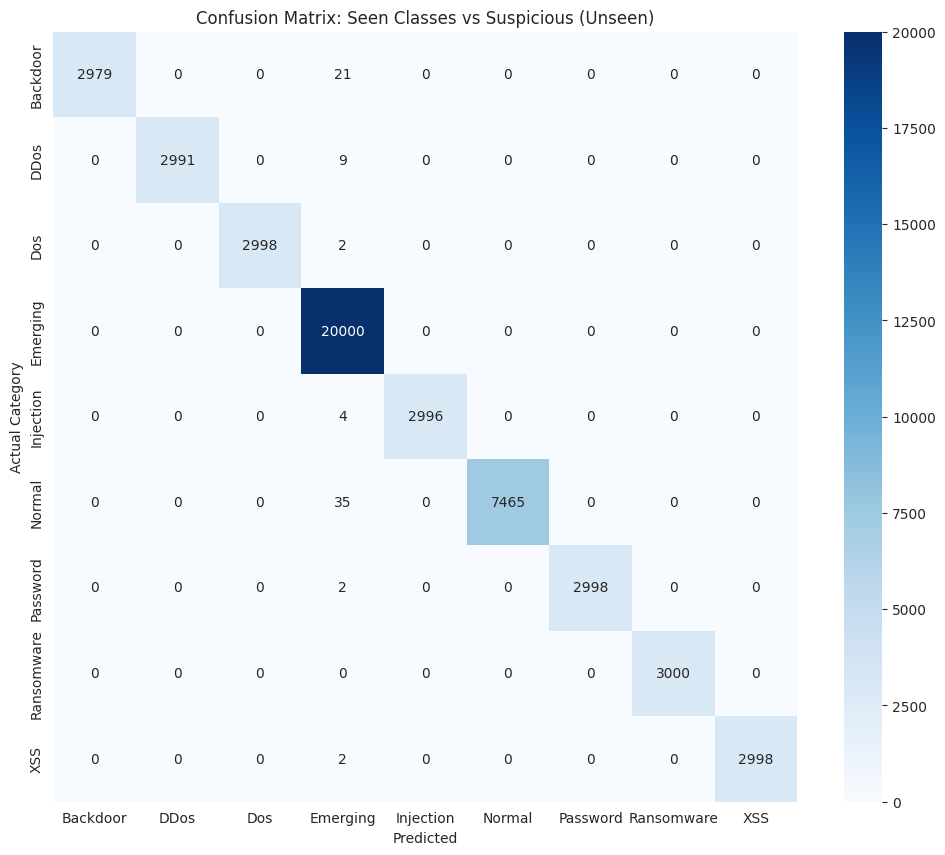


--- Detailed Analysis of Unseen Attack Detection ---


In [21]:
def predict_gtrs(model, loader, thresholds, le, temperature=1.0):
    model.eval()
    preds = []
    
    with torch.no_grad():
        for inputs, _ in loader: # Ignore dummy labels
            inputs = inputs.to(device)
            outputs = model(inputs)
            
            # SOLUTION 3: Temperature Scaling during inference
            # Divides logits by T > 1 to soften distribution
            probs_batch = torch.softmax(outputs / temperature, dim=1).cpu().numpy()
            
            for i in range(len(probs_batch)):
                p_vec = probs_batch[i]
                pred_idx = np.argmax(p_vec)
                conf = p_vec[pred_idx]
                
                t = thresholds[pred_idx]
                
                if conf >= t['alpha']:
                    preds.append(le.inverse_transform([pred_idx])[0])
                else:
                    preds.append('Emerging')
                    
    return np.array(preds)

print("\nRunning Inference on Mixed Test Set...")
y_pred = predict_gtrs(model, test_loader, opt_thresholds, le )

#%% [markdown]
# ## 8. Evaluation

y_true_mapped = []
for label in y_test_final_str:
    if label in UNSEEN_CLASSES:
        y_true_mapped.append('Emerging')
    else:
        y_true_mapped.append(label)

print("\nClassification Report:")
print(classification_report(y_true_mapped, y_pred))

# Confusion Matrix
plt.figure(figsize=(12, 10))
labels = sorted(list(set(y_true_mapped) | set(y_pred)))
cm = confusion_matrix(y_true_mapped, y_pred, labels=labels)

report_dict=report_dict = classification_report(
    y_true_mapped,
    y_pred,
    output_dict=True,
    zero_division=0
)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix: Seen Classes vs Suspicious (Unseen)")
plt.ylabel('Actual Category')
plt.xlabel('Predicted')
plt.savefig('confusion_matrix_ton_iot.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n--- Detailed Analysis of Unseen Attack Detection ---")
analysis_df = pd.DataFrame({
    'Actual_Category': y_test_final_str,
    'Prediction': y_pred
})


Running Inference on Mixed Test Set...

PART A: SEEN (KNOWN) ATTACKS


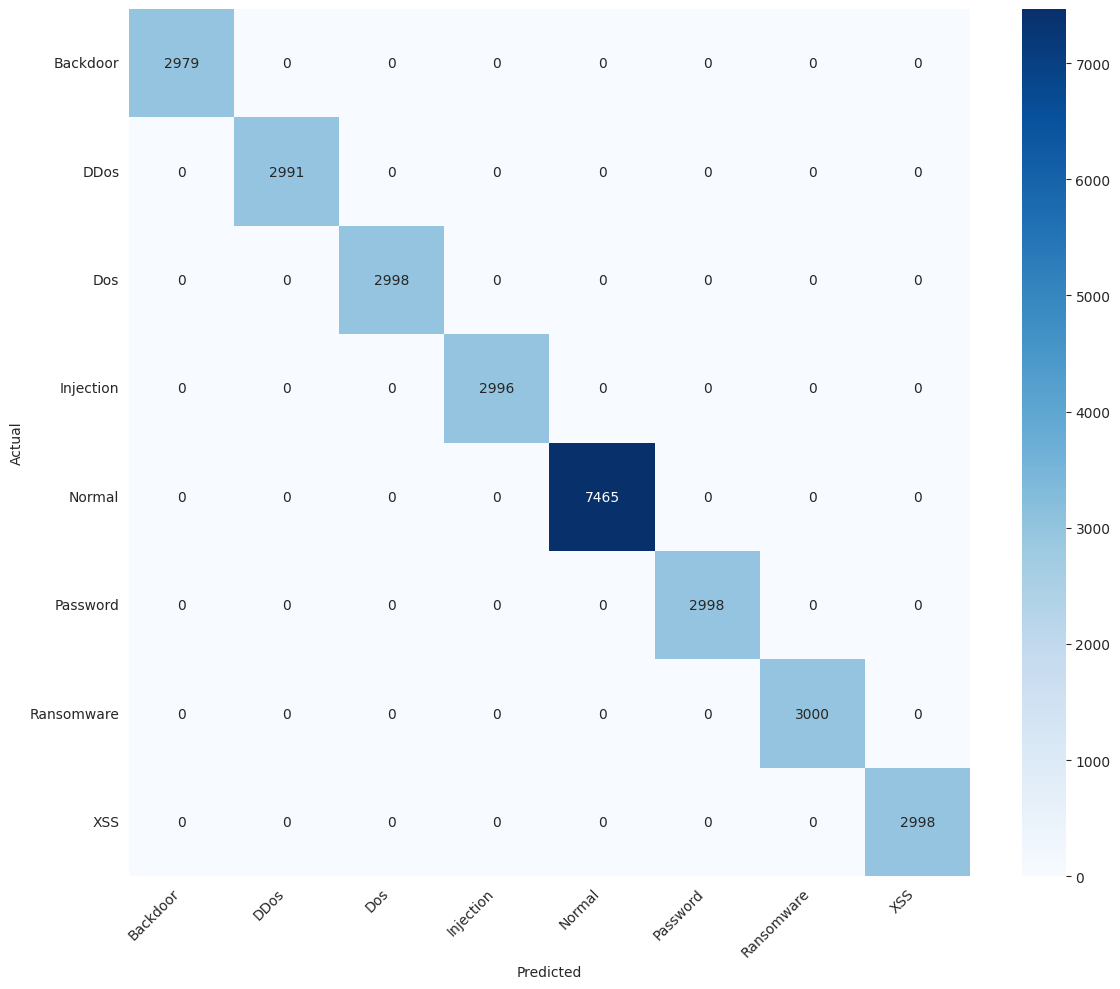

unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.


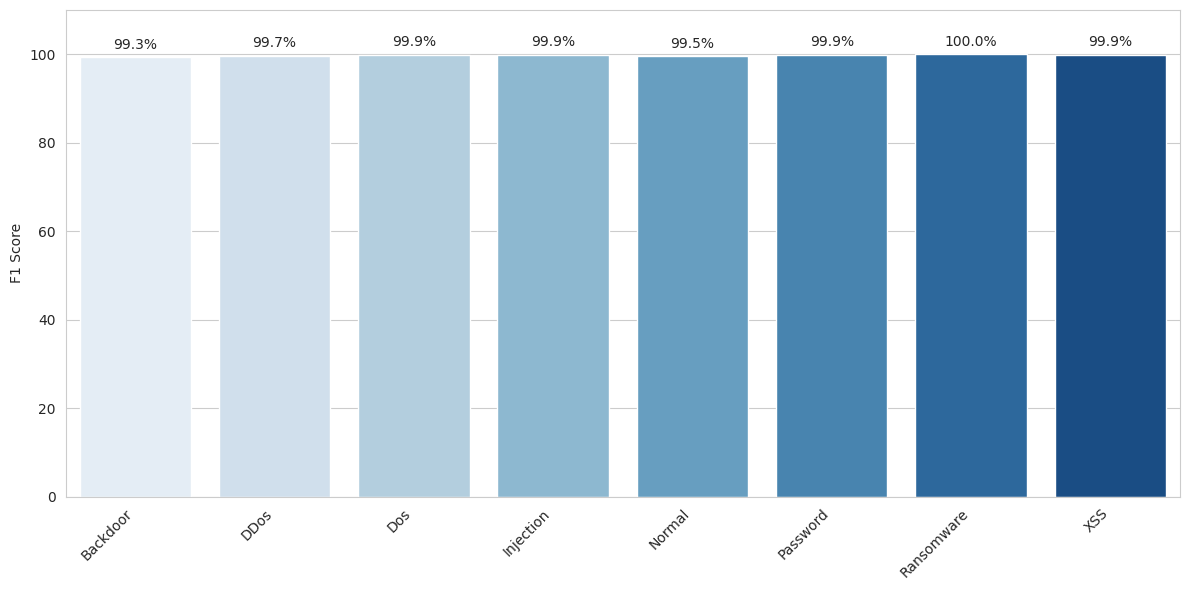


PART B: UNSEEN (UNKNOWN) ATTACKS


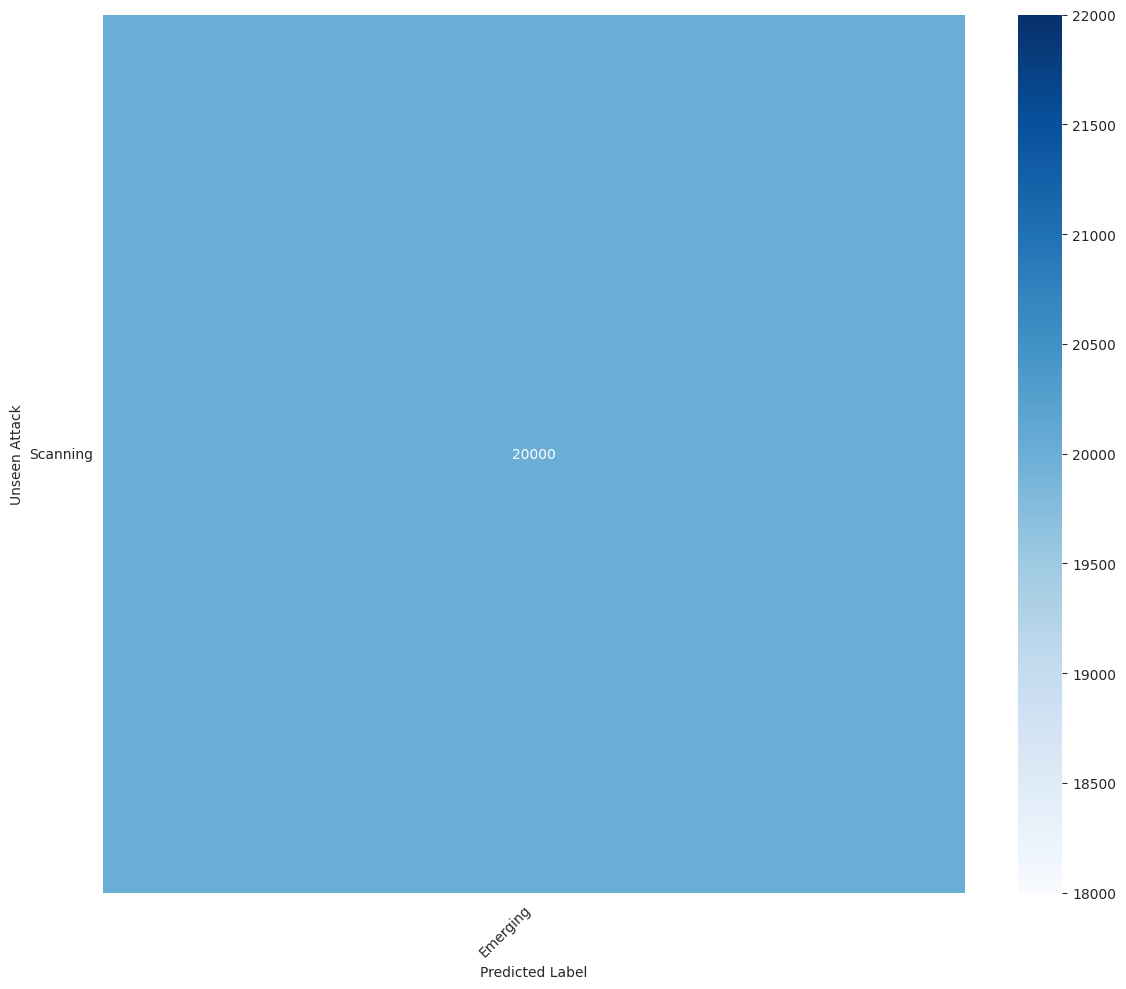

When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.


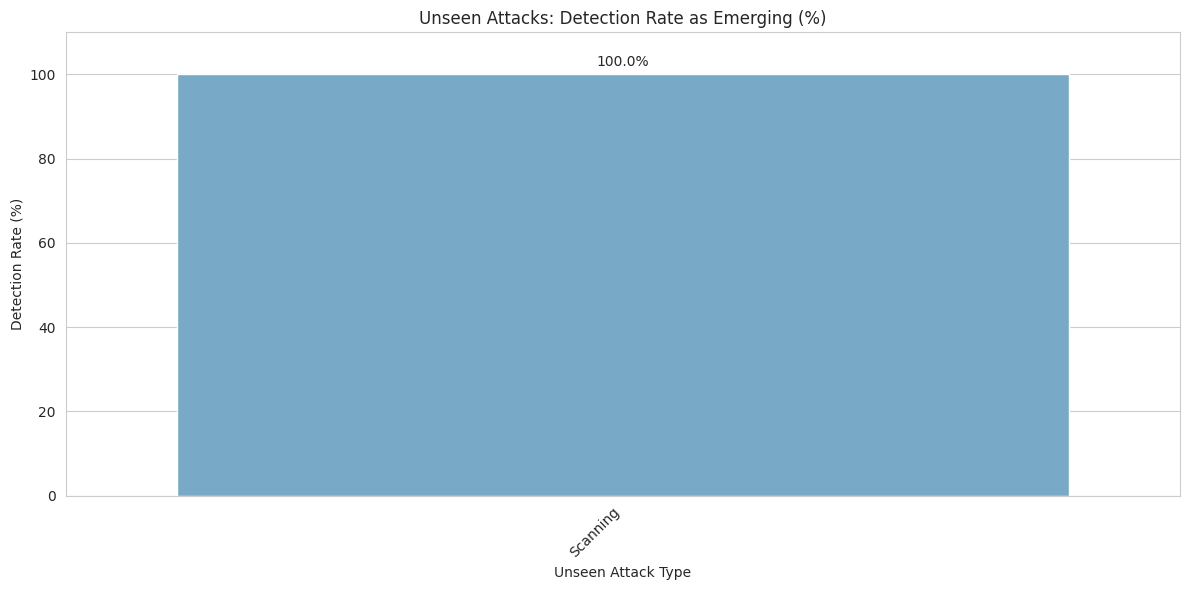


Charts saved:
1) confusion_seen_attacks_blues.png
2) bar_seen_recall_blues.png
3) confusion_unseen_attacks_blues.png
4) bar_unseen_detection_rate_blues.png


In [17]:
print("\nRunning Inference on Mixed Test Set...")
y_pred = predict_gtrs(model, test_loader, opt_thresholds, le)

# Ensure numpy arrays
y_true_all = np.asarray(y_test_final_str)
y_pred_all = np.asarray(y_pred)

# Safety: align lengths
n = min(len(y_true_all), len(y_pred_all))
if len(y_true_all) != len(y_pred_all):
    print(f"[WARN] Length mismatch y_true={len(y_true_all)} vs y_pred={len(y_pred_all)}. Truncating to n={n}.")
y_true_all = y_true_all[:n]
y_pred_all = y_pred_all[:n]

known_classes = set(le.classes_)
is_seen_mask = np.array([lbl in known_classes for lbl in y_true_all])

y_true_seen = y_true_all[is_seen_mask]
y_pred_seen = y_pred_all[is_seen_mask]

y_true_unseen = y_true_all[~is_seen_mask]
y_pred_unseen = y_pred_all[~is_seen_mask]

# Consistent BLUE scheme everywhere
BLUE_CMAP = "Blues"
sns.set_style("whitegrid")


# ============================
# PART A: SEEN ATTACKS
#   - Confusion Matrix (NO Emerging)
#   - Recall Bar Chart with % on top (NO Emerging)
# ============================
print("\n" + "="*55)
print("PART A: SEEN (KNOWN) ATTACKS")
print("="*55)

if len(y_true_seen) == 0:
    print("No Seen samples in this test set.")
else:
    # Confusion Matrix for seen attacks (remove Emerging column + optionally Emerging row)
    df_cm_seen = pd.crosstab(
        pd.Series(y_true_seen, name="Actual"),
        pd.Series(y_pred_seen, name="Predicted")
    )

    # Remove 'Emerging' from seen CM (both as predicted and actual if present)
    if "Emerging" in df_cm_seen.columns:
        df_cm_seen = df_cm_seen.drop(columns=["Emerging"])
    if "Emerging" in df_cm_seen.index:
        df_cm_seen = df_cm_seen.drop(index=["Emerging"])

    plt.figure(figsize=(12, 10))
    sns.heatmap(df_cm_seen, annot=True, fmt="d", cmap=BLUE_CMAP)
    plt.title("")  # keep blank like you prefer
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig("confusion_seen_attacks_blues.png", dpi=300)
    plt.show()

    # Recall bar chart for seen attacks (exclude Emerging)
    seen_report = classification_report(
        y_true_seen,
        y_pred_seen,
        output_dict=True,
        zero_division=0
    )

    seen_classes = [
        k for k in seen_report.keys()
        if k not in ["accuracy", "macro avg", "weighted avg", "Emerging"]
    ]
    seen_recall_pct = [seen_report[c]["recall"] * 100 for c in seen_classes]

    plt.figure(figsize=(12, 6))
    ax = sns.barplot(
        x=seen_classes,
        y=seen_recall_pct,
        palette=sns.color_palette(BLUE_CMAP, n_colors=len(seen_classes))
    )
    plt.title("")
    plt.ylabel("F1 Score")
    plt.xlabel("")
    plt.xticks(rotation=45, ha="right")
    plt.ylim(0, 110)

    # Values on top of bars
    for p, val in zip(ax.patches, seen_recall_pct):
        ax.annotate(
            f"{val:.1f}%",
            (p.get_x() + p.get_width()/2, p.get_height()),
            ha="center", va="bottom",
            fontsize=10,
            xytext=(0, 4), textcoords="offset points"
        )

    plt.tight_layout()
    plt.savefig("bar_seen_recall_blues.png", dpi=300)
    plt.show()


# ============================
# PART B: UNSEEN ATTACKS
#   - Confusion Matrix (Actual unseen types vs predicted labels)
#   - Recall-like bar chart: detection rate (% predicted as Emerging) with % on top
# ============================
print("\n" + "="*55)
print("PART B: UNSEEN (UNKNOWN) ATTACKS")
print("="*55)

if len(y_true_unseen) == 0:
    print("No Unseen samples in this test set.")
else:
    # Confusion Matrix for unseen attacks (rows=actual unseen, cols=pred labels)
    df_cm_unseen = pd.crosstab(
        pd.Series(y_true_unseen, name="Unseen Attack"),
        pd.Series(y_pred_unseen, name="Predicted Label")
    )

    # Put 'Emerging' first if present (optional)
    cols = list(df_cm_unseen.columns)
    if "Emerging" in cols:
        cols.remove("Emerging")
        cols.insert(0, "Emerging")
        df_cm_unseen = df_cm_unseen[cols]

    plt.figure(figsize=(12, 10))
    sns.heatmap(df_cm_unseen, annot=True, fmt="d", cmap=BLUE_CMAP)
    plt.title("")  # keep blank
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig("confusion_unseen_attacks_blues.png", dpi=300)
    plt.show()

    # "Recall" for unseen = Detection rate (% predicted as Emerging) per unseen attack type
    unseen_df = pd.DataFrame({"Actual": y_true_unseen, "Predicted": y_pred_unseen})
    unseen_rates = (
        unseen_df.groupby("Actual")["Predicted"]
        .apply(lambda x: (x == "Emerging").mean() * 100)
        .reset_index()
        .rename(columns={"Actual": "Unseen Attack Type", "Predicted": "Detection Rate (%)"})
        .sort_values("Detection Rate (%)", ascending=False)
    )

    plt.figure(figsize=(12, 6))
    ax2 = sns.barplot(
        data=unseen_rates,
        x="Unseen Attack Type",
        y="Detection Rate (%)",
        palette=sns.color_palette(BLUE_CMAP, n_colors=len(unseen_rates))
    )
    plt.title("Unseen Attacks: Detection Rate as Emerging (%)")
    plt.ylabel("Detection Rate (%)")
    plt.xlabel("Unseen Attack Type")
    plt.xticks(rotation=45, ha="right")
    plt.ylim(0, 110)

    # Values on top of bars
    for p, val in zip(ax2.patches, unseen_rates["Detection Rate (%)"].tolist()):
        ax2.annotate(
            f"{val:.1f}%",
            (p.get_x() + p.get_width()/2, p.get_height()),
            ha="center", va="bottom",
            fontsize=10,
            xytext=(0, 4), textcoords="offset points"
        )

    plt.tight_layout()
    plt.savefig("bar_unseen_detection_rate_blues.png", dpi=300)
    plt.show()

print("\nCharts saved:")
print("1) confusion_seen_attacks_blues.png")
print("2) bar_seen_recall_blues.png")
print("3) confusion_unseen_attacks_blues.png")
print("4) bar_unseen_detection_rate_blues.png")

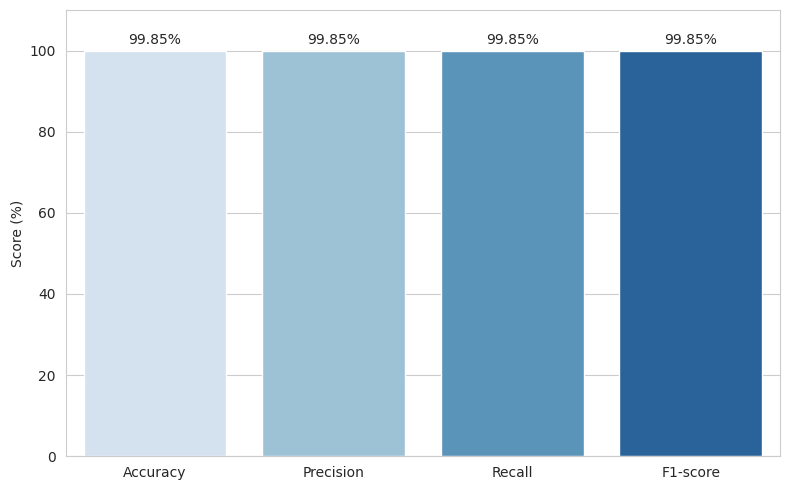

In [24]:
cmap_name = "Blues"
# ==========================================
# 4) Overall Metrics Visualization (Accuracy, Precision, Recall, F1)
# ==========================================

# Get overall metrics (use weighted avg for multi-class)
acc = report_dict["accuracy"] * 100
prec = report_dict["weighted avg"]["precision"] * 100
rec = report_dict["weighted avg"]["recall"] * 100
f1 = report_dict["weighted avg"]["f1-score"] * 100

overall_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score (%)": [acc, prec, rec, f1]
})

plt.figure(figsize=(8, 5))
ax_overall = sns.barplot(
    data=overall_df,
    x="Metric",
    y="Score (%)",
    palette=sns.color_palette(cmap_name, n_colors=len(overall_df))
)

plt.title("")
plt.ylabel("Score (%)")
plt.xlabel("")
plt.ylim(0, 110)

# Add values on top of bars
for container in ax_overall.containers:
    ax_overall.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.savefig("overall_seen_metrics.png", dpi=300)
plt.show()


In [102]:
data = pd.read_csv("/kaggle/input/ton-iot-network-dataset/train_test_network.csv")

In [4]:
data["label"].value_counts()

label
1    161043
0     50000
Name: count, dtype: int64

In [17]:
len(data.columns)

44

In [39]:
data['type'].value_counts()

type
normal        50000
backdoor      20000
ddos          20000
dos           20000
injection     20000
password      20000
scanning      20000
ransomware    20000
xss           20000
mitm           1043
Name: count, dtype: int64

In [103]:
plt.savefig("Confusion_matrix.png")

<Figure size 640x480 with 0 Axes>


--- Generating ROC Curves ---


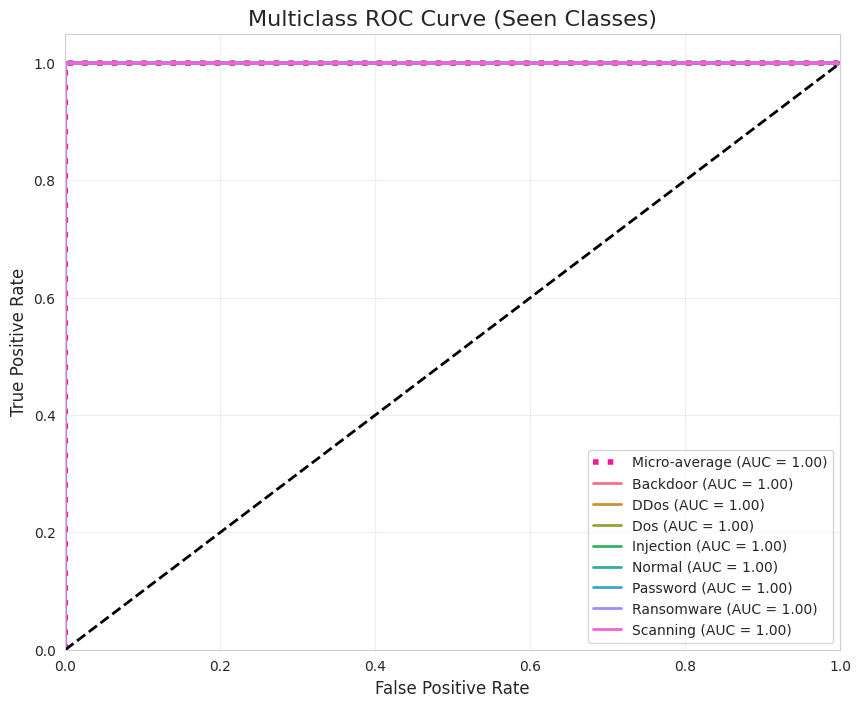


All charts generated and saved.


In [37]:
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.metrics import confusion_matrix, classification_report, f1_score, roc_curve, auc, accuracy_score, precision_recall_fscore_support
from itertools import cycle
print("\n--- Generating ROC Curves ---")
# Filter test set to only include SEEN classes for valid ROC calculation
mask_seen = np.isin(y_test_final_str, SEEN_CLASSES)
y_test_seen_only = y_test_final_str[mask_seen]
X_test_seen_only = X_test_final[mask_seen] 

# Create a temporary loader
seen_ds = IoTDataset(X_test_seen_only, np.zeros(len(X_test_seen_only))) 
seen_loader = DataLoader(seen_ds, batch_size=CONFIG['batch_size'], shuffle=False)

# Get raw probabilities
probs_seen, _ = get_probabilities(model, seen_loader) 

# Binarize labels
classes = list(le.classes_)
y_test_bin = label_binarize(y_test_seen_only, classes=classes)
n_classes = y_test_bin.shape[1]

# Plot
plt.figure(figsize=(10, 8))
fpr = dict()
tpr = dict()
roc_auc = dict()

# Calculate micro-average
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), probs_seen.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

plt.plot(fpr["micro"], tpr["micro"],
         label='Micro-average (AUC = {0:0.2f})'.format(roc_auc["micro"]),
         color='deeppink', linestyle=':', linewidth=4)

# Plot each class
colors = cycle(sns.color_palette("husl", n_classes)) # Distinct colors for lines
for i, color in zip(range(n_classes), colors):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], probs_seen[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='{0} (AUC = {1:0.2f})'.format(classes[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Multiclass ROC Curve (Seen Classes)', fontsize=16)
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.savefig('/kaggle/working/multiclass_roc_curve.png', dpi=300)
plt.show()

print("\nAll charts generated and saved.")

In [4]:
columns=list(pd.read_csv("/kaggle/input/ton-iot-network-dataset/train_test_network.csv").columns)

In [6]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap
from sklearn.preprocessing import StandardScaler
import lime

# --- 1. Define Model Architecture (Must match training exactly) ---
class CNNTransformerBiLSTM(nn.Module):
    def __init__(self, input_len, num_classes):
        super(CNNTransformerBiLSTM, self).__init__()
        # CNN
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2) 
        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        # Transformer
        encoder_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        # BiLSTM
        self.lstm = nn.LSTM(input_size=128, hidden_size=64, bidirectional=True, batch_first=True)
        # Classifier
        self.fc1 = nn.Linear(64*2, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out = nn.Linear(64, num_classes)
        
    def forward(self, x):
        x = x.permute(0, 2, 1) 
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x)) 
        x = x.permute(0, 2, 1) 
        x = self.transformer(x)
        _, (h_n, _) = self.lstm(x)
        x = torch.cat((h_n[-2,:,:], h_n[-1,:,:]), dim=1)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc_out(x)
        return x

# --- 2. Configuration & Setup ---
CONFIG = {
    'model_path': '/kaggle/working/gtrs_final_model.pth',
    'input_shape': (44, 1), 
    'num_classes': 8 
}

# SEEN_CLASSES = ['Mirai_UDP', 'Mirai_SYN', 'Mirai_ACK', 'Gafgyt_TCP', 'Mirai_UDPPlain', 'Gafgyt_Combo', 'benign', 'Gafgyt_Junk']

# Explicit Feature Names from CICIoT2023 Dataset
FEATURE_NAMES = columns
# Validate feature count matches config
if len(FEATURE_NAMES) != CONFIG['input_shape'][0]:
    print(f"Warning: Feature name list length ({len(FEATURE_NAMES)}) does not match input shape ({CONFIG['input_shape'][0]}). Truncating or padding.")
    if len(FEATURE_NAMES) > CONFIG['input_shape'][0]:
        FEATURE_NAMES = FEATURE_NAMES[:CONFIG['input_shape'][0]]
    else:
        FEATURE_NAMES += [f"Feature_{i}" for i in range(len(FEATURE_NAMES), CONFIG['input_shape'][0])]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 3. Load Model ---
print("Loading model...")
model = CNNTransformerBiLSTM(input_len=CONFIG['input_shape'][0], num_classes=CONFIG['num_classes']).to(device)
try:
    model.load_state_dict(torch.load(CONFIG['model_path'], map_location=device))
    print("Model loaded successfully.")
except FileNotFoundError:
    print("Warning: Saved model not found. Using initialized weights for demonstration.")

model.eval()

# --- 4. Prepare Background Data ---
print("Preparing background data...")
# We generate a synthetic background (replace with X_train sample in real usage)
background_data_np = np.random.rand(50, CONFIG['input_shape'][0]).astype(np.float32)

# Define prediction function for KernelExplainer/LIME
def predict_proba_shap(data_numpy):
    data_tensor = torch.tensor(data_numpy, dtype=torch.float32).unsqueeze(2).to(device)
    with torch.no_grad():
        logits = model(data_tensor)
        probs = torch.softmax(logits, dim=1)
    return probs.cpu().numpy()

# --- 5. LIME Explanations (Per-Class) ---
print("\n--- Initializing LIME Explainer ---")
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=background_data_np, # Ideally use X_train
    feature_names=FEATURE_NAMES,
    class_names=SEEN_CLASSES,
    mode='classification',
    discretize_continuous=True
)

# Generate dummy test data for demonstration (Replace with X_test in real usage)
test_data_np = np.random.rand(50, CONFIG['input_shape'][0]).astype(np.float32) 

# Get predictions to find representative samples for each class
test_probs = predict_proba_shap(test_data_np)
test_preds = np.argmax(test_probs, axis=1)

print("\nGenerating Per-Class LIME Explanations...")

for class_idx, class_name in enumerate(SEEN_CLASSES):
    # Find a sample predicted as this class
    sample_indices = np.where(test_preds == class_idx)[0]
    
    if len(sample_indices) == 0:
        print(f"Skipping Class '{class_name}' - No samples predicted as this class in test subset.")
        continue
        
    sample_idx = sample_indices[0] # Pick the first sample found for this class
    print(f"--> Generating LIME plots for Class: {class_name} (Sample Index: {sample_idx})")
    
    # Generate LIME explanation
    # num_features=10: Show top 10 contributing features
    exp = lime_explainer.explain_instance(
        data_row=test_data_np[sample_idx], 
        predict_fn=predict_proba_shap, 
        num_features=10, 
        top_labels=1
    )
    
    # 1. Save Explanation as HTML (Interactive)
    html_filename = f'lime_explanation_{class_name}.html'
    exp.save_to_file(html_filename)
    print(f"   Saved HTML explanation to {html_filename}")
    
    # 2. Generate Feature Contribution Plot (Right side of Paper Fig 12)
    fig = exp.as_pyplot_figure(label=class_idx)
    plt.title(f"LIME Feature Contributions: {class_name}")
    plt.tight_layout()
    plt.savefig(f'lime_feature_plot_{class_name}.png')
    plt.close()
    
    # 3. Generate Prediction Probabilities Plot (Left side of Paper Fig 12)
    # Get probs for this specific sample
    sample_probs = test_probs[sample_idx]
    
    plt.figure(figsize=(6, 4))
    # Create horizontal bar chart
    y_pos = np.arange(len(SEEN_CLASSES))
    plt.barh(y_pos, sample_probs, align='center', color='skyblue')
    plt.yticks(y_pos, SEEN_CLASSES)
    plt.xlabel('Probability')
    plt.title(f'Prediction Probabilities (Sample {sample_idx})')
    plt.xlim(0, 1.05) # Probability is 0-1
    
    # Add value labels
    for i, v in enumerate(sample_probs):
        plt.text(v + 0.01, i, f"{v:.2f}", color='black', va='center')
        
    plt.tight_layout()
    plt.savefig(f'lime_probability_plot_{class_name}.png')
    plt.close()

print("\nLIME analysis complete. Check generated HTML and PNG files.")

# --- 6. SHAP Visualizations (Existing code) ---
print("\n--- Starting SHAP Analysis ---")
explainer = shap.KernelExplainer(predict_proba_shap, background_data_np)
shap_values = explainer.shap_values(test_data_np, nsamples=100)

# A. Global Summary Plot
print("Generating Global Summary Plot...")
plt.figure()
shap.summary_plot(shap_values, test_data_np, feature_names=FEATURE_NAMES, class_names=SEEN_CLASSES, show=False)
plt.title("SHAP Summary Plot (Global Explanation)")
plt.tight_layout()
plt.savefig('shap_summary_plot_global.png')
plt.close()
print("Saved 'shap_summary_plot_global.png'")

# B. Per-Class SHAP Plots
print("\nGenerating Per-Class SHAP Explanation Plots...")
for class_idx, class_name in enumerate(SEEN_CLASSES):
    sample_indices = np.where(test_preds == class_idx)[0]
    if len(sample_indices) == 0: continue
    sample_idx = sample_indices[0]
    
    # Decision Plot
    plt.figure()
    base_val = explainer.expected_value[class_idx]
    shap.decision_plot(
        base_val, 
        shap_values[class_idx][sample_idx], 
        test_data_np[sample_idx], 
        feature_names=FEATURE_NAMES,
        show=False,
        title=f"Decision Plot: {class_name}"
    )
    plt.tight_layout()
    plt.savefig(f'shap_decision_plot_{class_name}.png')
    plt.close()
    
    # Waterfall Plot
    plt.figure()
    try:
        exp = shap.Explanation(
            values=shap_values[class_idx][sample_idx],
            base_values=base_val,
            data=test_data_np[sample_idx],
            feature_names=FEATURE_NAMES
        )
        shap.waterfall_plot(exp, show=False)
        plt.title(f"Waterfall Plot: {class_name}")
        plt.tight_layout()
        plt.savefig(f'shap_waterfall_plot_{class_name}.png')
        plt.close()
    except Exception as e:
        print(f"   Waterfall plot failed for {class_name}: {e}")

print("\nAll Explainable AI charts generated.")

Loading model...
Model loaded successfully.
Preparing background data...

--- Initializing LIME Explainer ---

Generating Per-Class LIME Explanations...
Skipping Class 'Normal' - No samples predicted as this class in test subset.
Skipping Class 'Ransomware' - No samples predicted as this class in test subset.
Skipping Class 'Backdoor' - No samples predicted as this class in test subset.
Skipping Class 'Injection' - No samples predicted as this class in test subset.
--> Generating LIME plots for Class: Scanning (Sample Index: 1)
   Saved HTML explanation to lime_explanation_Scanning.html
--> Generating LIME plots for Class: DDos (Sample Index: 0)
   Saved HTML explanation to lime_explanation_DDos.html
Skipping Class 'XSS' - No samples predicted as this class in test subset.
Skipping Class 'Dos' - No samples predicted as this class in test subset.

LIME analysis complete. Check generated HTML and PNG files.

--- Starting SHAP Analysis ---


  0%|          | 0/50 [00:00<?, ?it/s]

Generating Global Summary Plot...


The figure layout has changed to tight


Saved 'shap_summary_plot_global.png'

Generating Per-Class SHAP Explanation Plots...

All Explainable AI charts generated.
